# Experiment 1 — Exploratory Data Analysis (House Price Dataset)

**Covers:** Dataset information, descriptive statistics, histograms, correlation matrix, heatmap and strongest correlation pairs.

**Dataset:** **House Price – California Housing** – `housing.csv` from Kaggle ([camnugent/california-housing-prices](https://www.kaggle.com/datasets/camnugent/california-housing-prices)), 20,640 districts, target `median_house_value`, plus income, house age, rooms, population, location and `ocean_proximity`.

**Data file:** keep `housing.csv` in the **same folder as this notebook** (or replace the file name with its full path, e.g. `pd.read_csv(r"C:\Users\Lab\Desktop\housing.csv")`).

**Remember:** Load → Describe → Histograms → Correlation → Heatmap → Strongest pairs.

## Import libraries and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("housing.csv")

## 1. Dataset information

In [2]:
print(df.head())
print(df.shape)
df.info()
print(df.isnull().sum())

   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  
(20640, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries

## 2. Descriptive statistics

In [3]:
num = df[["housing_median_age", "total_rooms", "total_bedrooms", "population",
           "households", "median_income", "median_house_value"]]
print(num.describe())
print(num.agg(["median", "var", "skew", "kurt"]))
print(df["ocean_proximity"].value_counts())

       housing_median_age   total_rooms  total_bedrooms    population  \
count        20640.000000  20640.000000    20433.000000  20640.000000   
mean            28.639486   2635.763081      537.870553   1425.476744   
std             12.585558   2181.615252      421.385070   1132.462122   
min              1.000000      2.000000        1.000000      3.000000   
25%             18.000000   1447.750000      296.000000    787.000000   
50%             29.000000   2127.000000      435.000000   1166.000000   
75%             37.000000   3148.000000      647.000000   1725.000000   
max             52.000000  39320.000000     6445.000000  35682.000000   

         households  median_income  median_house_value  
count  20640.000000   20640.000000        20640.000000  
mean     499.539680       3.870671       206855.816909  
std      382.329753       1.899822       115395.615874  
min        1.000000       0.499900        14999.000000  
25%      280.000000       2.563400       119600.000000  


## 3. Histograms

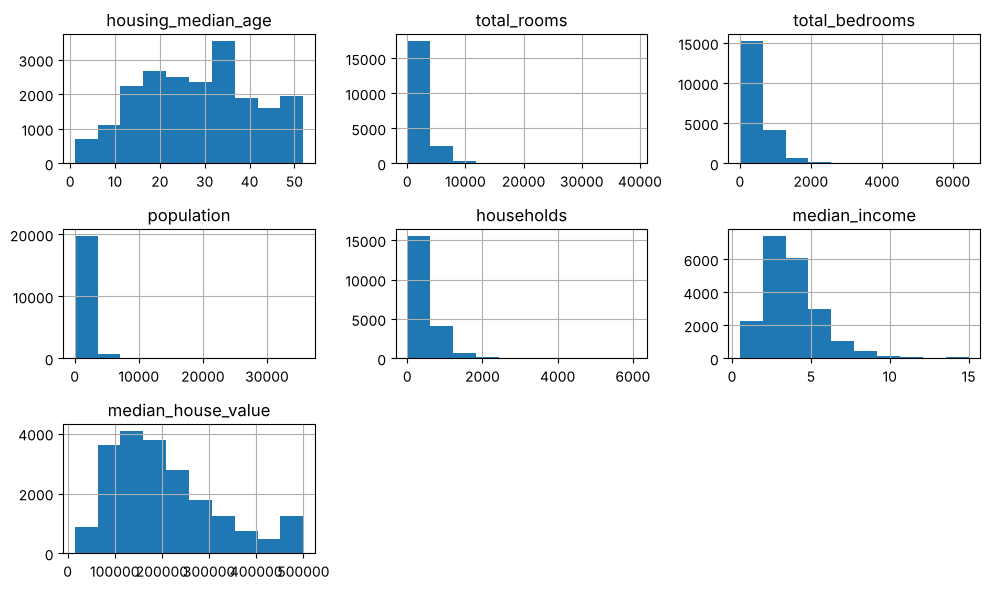

In [4]:
num.hist(bins=10, figsize=(10, 6))
plt.tight_layout()
plt.show()

## 4. Correlation matrix and heatmap

                    housing_median_age  total_rooms  total_bedrooms  \
housing_median_age            1.000000    -0.361262       -0.320451   
total_rooms                  -0.361262     1.000000        0.930380   
total_bedrooms               -0.320451     0.930380        1.000000   
population                   -0.296244     0.857126        0.877747   
households                   -0.302916     0.918484        0.979728   
median_income                -0.119034     0.198050       -0.007723   
median_house_value            0.105623     0.134153        0.049686   

                    population  households  median_income  median_house_value  
housing_median_age   -0.296244   -0.302916      -0.119034            0.105623  
total_rooms           0.857126    0.918484       0.198050            0.134153  
total_bedrooms        0.877747    0.979728      -0.007723            0.049686  
population            1.000000    0.907222       0.004834           -0.024650  
households            0.907222 

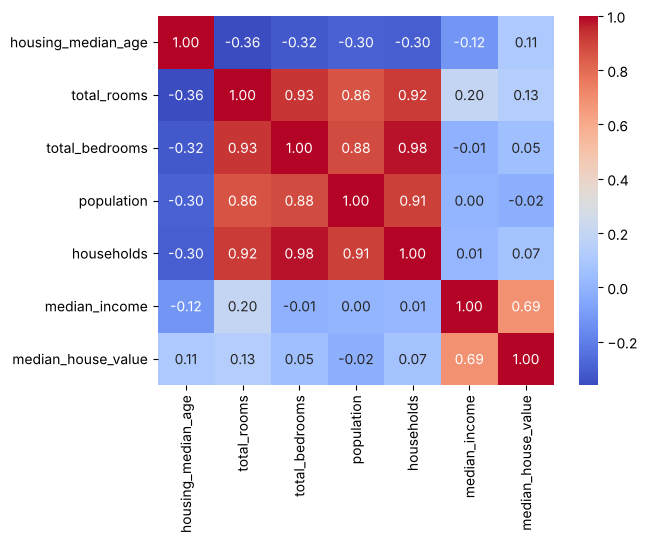

In [5]:
corr = num.corr()
print(corr)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

## 5. Strongest correlations

In [6]:
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print(pairs.sort_values(key=abs, ascending=False).head(10))

total_bedrooms      households            0.979728
total_rooms         total_bedrooms        0.930380
                    households            0.918484
population          households            0.907222
total_bedrooms      population            0.877747
total_rooms         population            0.857126
median_income       median_house_value    0.688075
housing_median_age  total_rooms          -0.361262
                    total_bedrooms       -0.320451
                    households           -0.302916
dtype: float64


## 6. Location map coloured by house value

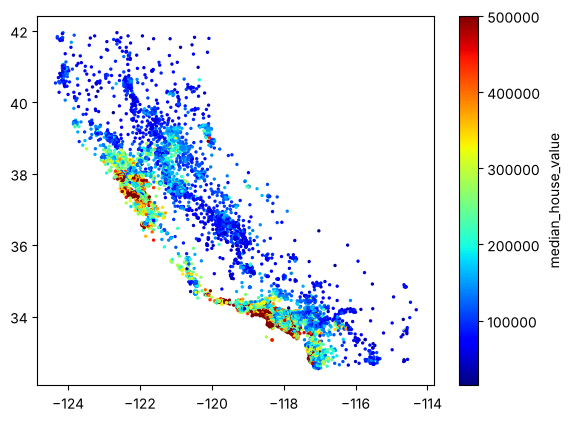

In [7]:
plt.scatter(df["longitude"], df["latitude"], c=df["median_house_value"], cmap="jet", s=2)
plt.colorbar(label="median_house_value")
plt.show()

## Result / Conclusion
- 20,640 districts, 10 columns; only `total_bedrooms` has missing values (207).
- `total_rooms`, `total_bedrooms`, `population` and `households` are heavily right-skewed (skew 3.5–4.9). House value is capped at 500,001.
- The size columns are almost duplicates of each other (`total_bedrooms`–`households` r = 0.98, `total_rooms`–`total_bedrooms` r = 0.93).
- `median_income` is the strongest predictor of house value (r = 0.69). The map shows the most expensive districts along the coast.